# Clinical Healthcare Data — Exploratory Data Analysis

This notebook explores a public healthcare dataset as part of the Clinical Intelligence Assistant project.

## Objectives

- Understand the dataset structure and features
- Check data quality and missing values
- Explore feature distributions and relationships
- Prepare the data for machine learning

In [1]:
import sys

print(sys.executable)
print(sys.version)

/opt/anaconda3/envs/clinical-ai/bin/python
3.11.17 (main, Oct  1 2026, 20:09:52) [Clang 20.1.8 ]


In [2]:
from ucimlrepo import fetch_ucirepo

# Fetch the UCI Heart Disease dataset
heart_disease = fetch_ucirepo(id=45)

# Separate input features and target
X = heart_disease.data.features
y = heart_disease.data.targets

print("Dataset loaded successfully!")
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Dataset loaded successfully!
Features shape: (303, 13)
Target shape: (303, 1)


In [3]:
X.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


In [4]:
y.head(10)

,num
0,0
1,2
2,1
3,0
4,0
5,0
6,3
7,0
8,2
9,1


In [5]:
y["num"].value_counts().sort_index()

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

In [6]:
X.dtypes

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
dtype: object

In [7]:
X.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
dtype: int64

In [8]:
X.duplicated().sum()

np.int64(0)

In [9]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [10]:
y_binary = (y["num"] > 0).astype(int)

y_binary.value_counts().sort_index()

num
0    164
1    139
Name: count, dtype: int64

In [11]:
y.isnull().sum()

num    0
dtype: int64

In [12]:
df = X.copy()
df["heart_disease"] = y_binary

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,heart_disease
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [13]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 303
Columns: 14


Matplotlib is building the font cache; this may take a moment.


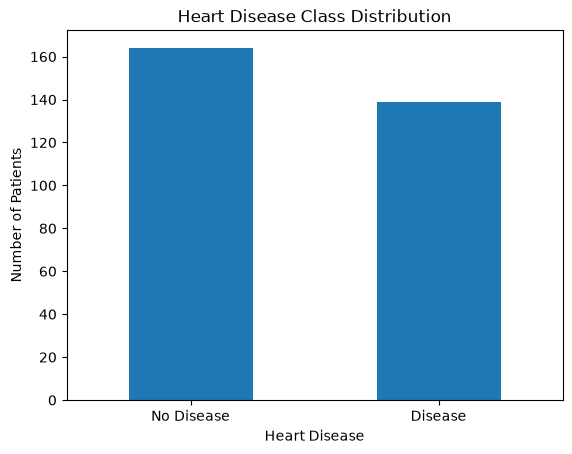

In [14]:
import matplotlib.pyplot as plt

df["heart_disease"].value_counts().sort_index().plot(kind="bar")

plt.title("Heart Disease Class Distribution")
plt.xlabel("Heart Disease")
plt.ylabel("Number of Patients")
plt.xticks([0, 1], ["No Disease", "Disease"], rotation=0)
plt.show()

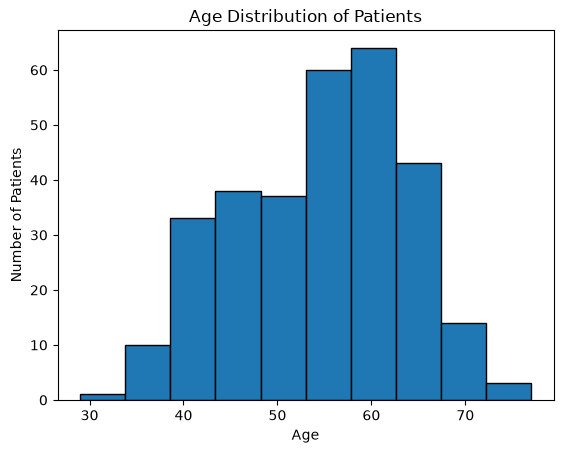

In [15]:
plt.hist(df["age"], bins=10, edgecolor="black")

plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()

In [16]:
df.groupby("heart_disease")["age"].mean()

heart_disease
0    52.585366
1    56.625899
Name: age, dtype: float64

In [17]:
df.groupby("heart_disease")["thalach"].mean()

heart_disease
0    158.378049
1    139.258993
Name: thalach, dtype: float64

In [18]:
df.groupby("heart_disease")["chol"].mean()

heart_disease
0    242.640244
1    251.474820
Name: chol, dtype: float64

In [19]:
df.groupby("heart_disease")["trestbps"].mean()

heart_disease
0    129.250000
1    134.568345
Name: trestbps, dtype: float64

In [22]:
import pandas as pd

In [23]:
pd.crosstab(df["cp"], df["heart_disease"])

heart_disease,0,1
cp,,
1,16,7
2,41,9
3,68,18
4,39,105


In [24]:
pd.crosstab(df["exang"], df["heart_disease"])

heart_disease,0,1
exang,,
0,141,63
1,23,76


In [25]:
df.corr(numeric_only=True)["heart_disease"].sort_values()

thalach         -0.417167
fbs              0.025264
chol             0.085164
trestbps         0.150825
restecg          0.169202
age              0.223120
sex              0.276816
slope            0.339213
cp               0.414446
oldpeak          0.424510
exang            0.431894
ca               0.460442
thal             0.525689
heart_disease    1.000000
Name: heart_disease, dtype: float64

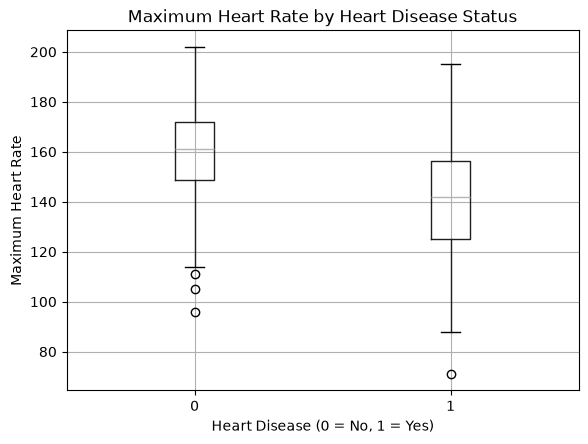

In [26]:
df.boxplot(column="thalach", by="heart_disease")

plt.title("Maximum Heart Rate by Heart Disease Status")
plt.suptitle("")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Maximum Heart Rate")
plt.show()

In [27]:
df.groupby("heart_disease")["oldpeak"].mean()

heart_disease
0    0.586585
1    1.574101
Name: oldpeak, dtype: float64

In [28]:
df.duplicated().sum()

np.int64(0)

In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   age            303 non-null    int64  
 1   sex            303 non-null    int64  
 2   cp             303 non-null    int64  
 3   trestbps       303 non-null    int64  
 4   chol           303 non-null    int64  
 5   fbs            303 non-null    int64  
 6   restecg        303 non-null    int64  
 7   thalach        303 non-null    int64  
 8   exang          303 non-null    int64  
 9   oldpeak        303 non-null    float64
 10  slope          303 non-null    int64  
 11  ca             299 non-null    float64
 12  thal           301 non-null    float64
 13  heart_disease  303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


In [30]:
df.to_csv("../data/heart_disease_eda.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!
